In [1]:
import pandas as pd
import matplotlib.pyplot as plt

daten = pd.read_csv("data/velo_wetter_2025.csv", parse_dates=["Datum"])
daten["monat"] = daten["Datum"].dt.month

print("Tage:", len(daten))
daten.head()

Tage: 365


,Datum,velos,temp_max,regen_mm,sonne_h,wochentag,wochenende,monat
0,2025-01-01,11104,5.3,0.0,5.233333,2,False,1
1,2025-01-02,15707,11.8,14.9,0.283333,3,False,1
2,2025-01-03,17789,2.1,0.0,1.916667,4,False,1
3,2025-01-04,14240,0.5,14.8,5.783333,5,True,1
4,2025-01-05,11561,6.3,1.0,0.000000,6,True,1


In [2]:
import requests

antwort = requests.get(
    "https://openholidaysapi.org/PublicHolidays",
    params={"countryIsoCode": "CH", "languageIsoCode": "DE",
            "validFrom": "2025-01-01", "validTo": "2025-12-31"},
    headers={"accept": "application/json"},
    timeout=30,
)

feiertage_bs = set()
for f in antwort.json():
    gilt_in_bs = f.get("nationwide") or any(
        r.get("code") == "CH-BS" for r in f.get("subdivisions", [])
    )
    if gilt_in_bs:
        feiertage_bs.add(pd.Timestamp(f["startDate"]))

daten["feiertag"] = daten["Datum"].isin(feiertage_bs)
print("Feiertage in Basel-Stadt 2025:", daten["feiertag"].sum())
daten[daten["feiertag"]][["Datum", "velos"]]

Feiertage in Basel-Stadt 2025: 10


,Datum,velos
0,2025-01-01,11104
107,2025-04-18,19692
110,2025-04-21,15444
120,2025-05-01,41092
148,2025-05-29,33059
159,2025-06-09,36834
212,2025-08-01,26035
263,2025-09-21,35585
358,2025-12-25,10779
359,2025-12-26,11475


In [6]:
MERKMALE = ["temp_max", "regen_mm", "sonne_h", "wochentag", "wochenende", "monat", "feiertag"]

X = daten[MERKMALE]   # was das Modell weiss
y = daten["velos"]    # was es vorhersagen soll

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Training:", len(X_train), "Tage · Test:", len(X_test), "Tage")

Training: 292 Tage · Test: 73 Tage


In [ ]:
# X = die Fragen (Wetter, Wochentag, …)
# y = die Antworten (Anzahl Velos)
# random_state=42 → Aufteilung jedes Mal gleich, damit Ergebnisse vergleichbar sind

In [7]:
from sklearn.metrics import mean_absolute_error

durchschnitt_pro_tag = y_train.groupby(X_train["wochentag"]).mean()
baseline = X_test["wochentag"].map(durchschnitt_pro_tag)

fehler_baseline = mean_absolute_error(y_test, baseline)
print(f"Baseline liegt im Schnitt um {fehler_baseline:,.0f} Velos daneben")

Baseline liegt im Schnitt um 8,308 Velos daneben


In [8]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score

modelle = {
    "Lineare Regression": LinearRegression(),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=42),
}

for name, modell in modelle.items():
    modell.fit(X_train, y_train)          # 📚 lernen
    vorhersage = modell.predict(X_test)   # 📝 Prüfung
    mae = mean_absolute_error(y_test, vorhersage)
    r2 = r2_score(y_test, vorhersage)
    print(f"{name:20s}  daneben: {mae:7,.0f} Velos   R²: {r2:.2f}")

Lineare Regression    daneben:   4,531 Velos   R²: 0.83
Random Forest         daneben:   4,586 Velos   R²: 0.81


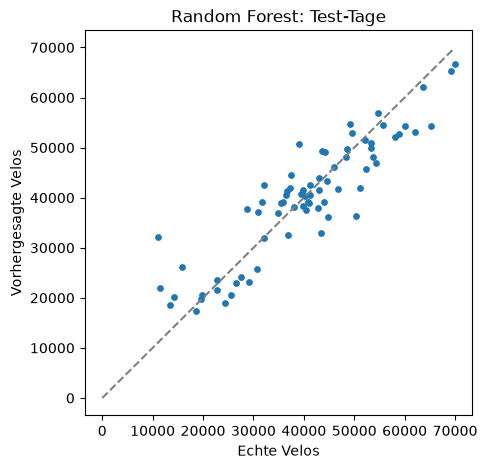

In [9]:
modell = modelle["Random Forest"]
vorhersage = modell.predict(X_test)

plt.figure(figsize=(5, 5))
plt.scatter(y_test, vorhersage, s=15)
grenze = [0, max(y_test.max(), vorhersage.max())]
plt.plot(grenze, grenze, "--", color="gray")  # perfekte Linie
plt.xlabel("Echte Velos")
plt.ylabel("Vorhergesagte Velos")
plt.title("Random Forest: Test-Tage")
plt.show()

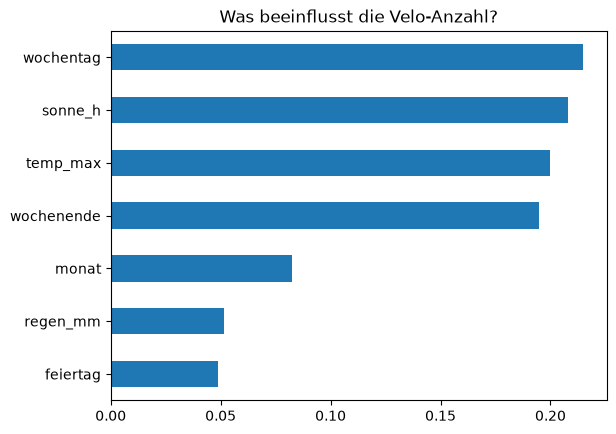

In [10]:
wichtigkeit = pd.Series(modell.feature_importances_, index=MERKMALE).sort_values()
wichtigkeit.plot.barh(title="Was beeinflusst die Velo-Anzahl?")
plt.show()

In [11]:
mein_tag = pd.DataFrame([{
    "temp_max": 18, "regen_mm": 0, "sonne_h": 8,
    "wochentag": 4, "wochenende": False, "monat": 5, "feiertag": False,
}])  # Freitag im Mai, 18°, sonnig

print(f"Vorhersage: {modell.predict(mein_tag)[0]:,.0f} Velos")

Vorhersage: 55,588 Velos
